# Entrega 2 - Solução e validação da recomendação de cultivo inteligente

**Disciplina:** Data Challenge 2026/2  
**Desafio:** Recomendação de cultivo inteligente com dados tabulares  
**Autores:** Diego Arruda Torales e Guilherme Zanini da Silva

## 1. Protocolo de validação e hipóteses

1. reserva estratificada de 20% para teste;
2. comparação e ajuste realizados somente nos 80% de treino;
3. validação cruzada estratificada com cinco partições;
4. seleção pelo F1 macro, pois todas as 22 culturas devem ter o mesmo peso;
5. abertura do teste uma única vez após a escolha do modelo final.

Hipóteses avaliadas:

- **H1:** modelos de ensemble baseados em árvores superam a regressão logística em F1 macro;
- **H2:** nutrientes e condições ambientais contribuem de forma desigual para a classificação;
- **H3:** retirar os registros com umidade acima de 100 altera pouco o F1 macro médio;
- **H4:** o desempenho cresce e estabiliza com mais dados, sem um aumento persistente do hiato treino-validação.

In [1]:
from pathlib import Path
import json
import platform
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from cultivo_inteligente import (
    DATASET_ID,
    FEATURES,
    RANDOM_STATE,
    TARGET,
    build_candidate_models,
    build_tuning_search,
    compare_models,
    confidence_diagnostics,
    evaluate_classifier,
    feature_ranges,
    fix_seeds,
    load_crop_data,
    recommend_top_k,
    validate_crop_data,
)

FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
for directory in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

fix_seeds(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
print(f"Raiz do projeto: {PROJECT_ROOT}")
print(f"Seed global: {RANDOM_STATE}")
print(f"Python: {platform.python_version()} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")

Raiz do projeto: /workspace
Seed global: 42
Python: 3.12.16 | pandas: 3.1.1 | scikit-learn: 1.9.1


## 2. Aquisição, procedência e validação

O enunciado original recomenda `srikanta28/Crop_Recommendation`. O projeto utiliza o caminho atualizado `randalakab/Crop-recommendation`, que disponibiliza o mesmo esquema de oito colunas. A API do Hugging Face identifica o CSV e registra a revisão da fonte.

In [2]:
raw_df, provenance = load_crop_data(PROJECT_ROOT)
df, diagnostics = validate_crop_data(raw_df)

display(pd.Series(provenance, name="valor").to_frame())
display(diagnostics)
display(df.head())
print(f"Dimensões validadas: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

,valor
dataset,randalakab/Crop-recommendation
arquivo,crop_recommendation.csv
fonte_utilizada,https://huggingface.co/datasets/randalakab/Cro...
tipo_fonte,Hugging Face
revisao_api,f154ba9e2c812c86ec6e24e9bfa14803d6db9689
ultima_modificacao_api,2026-03-18T05:15:09.000Z


,verificacao,resultado
0,registros,2200
1,colunas,8
2,valores ausentes,0
3,linhas duplicadas,0
4,culturas,22
5,menor classe,100
6,maior classe,100
7,umidade acima de 100,19


,N,P,K,temperature,humidity,ph,rainfall,label
0,93.183761,27.250831,74.277207,33.674623,94.914503,6.484254,32.683787,muskmelon
1,96.207721,19.879799,58.311558,30.074946,87.959344,6.755477,41.108275,watermelon
2,43.282444,20.270145,46.187129,34.166159,100.166220,7.390471,197.558965,papaya
3,59.798590,4.900153,41.490719,26.914239,92.876518,6.929745,147.476051,papaya
4,6.924168,137.545829,169.587918,23.536649,94.791895,5.777406,192.413493,apple


Dimensões validadas: 2,200 linhas x 8 colunas


,count,mean,std,min,25%,50%,75%,max,amplitude
N,2200.0,48.250,39.374,0.000,14.690,32.006,85.446,140.722,140.722
P,2200.0,48.450,31.712,0.000,23.449,44.604,61.332,152.116,152.116
K,2200.0,61.043,42.319,2.675,41.750,51.425,61.204,240.580,237.905
temperature,2200.0,25.574,6.233,0.828,22.011,26.123,29.622,41.728,40.901
humidity,2200.0,72.559,22.626,13.607,61.604,79.960,89.679,101.362,87.756
ph,2200.0,6.419,0.684,3.557,6.046,6.425,6.863,8.022,4.465
rainfall,2200.0,114.365,61.199,18.264,65.521,99.128,157.753,301.955,283.691


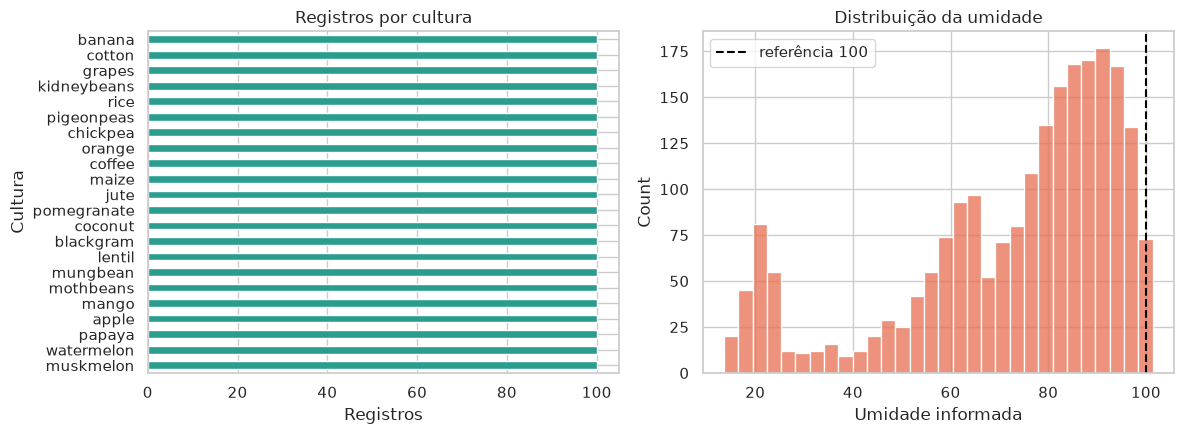

In [3]:
summary = df[FEATURES].describe().T
summary["amplitude"] = summary["max"] - summary["min"]
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df[TARGET].value_counts().sort_values().plot.barh(ax=axes[0], color="#2A9D8F")
axes[0].set(title="Registros por cultura", xlabel="Registros", ylabel="Cultura")
sns.histplot(df["humidity"], bins=30, color="#E76F51", ax=axes[1])
axes[1].axvline(100, color="black", linestyle="--", label="referência 100")
axes[1].set(title="Distribuição da umidade", xlabel="Umidade informada")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "diagnostico_dados_final.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Arquitetura do pipeline

O pipeline separa claramente aquisição, controle de qualidade, seleção no treino, avaliação final e inferência. O protótipo operacional acrescenta um aviso quando a entrada está fora das faixas observadas, reduzindo o risco de apresentar uma recomendação fora do domínio conhecido sem sinalização.

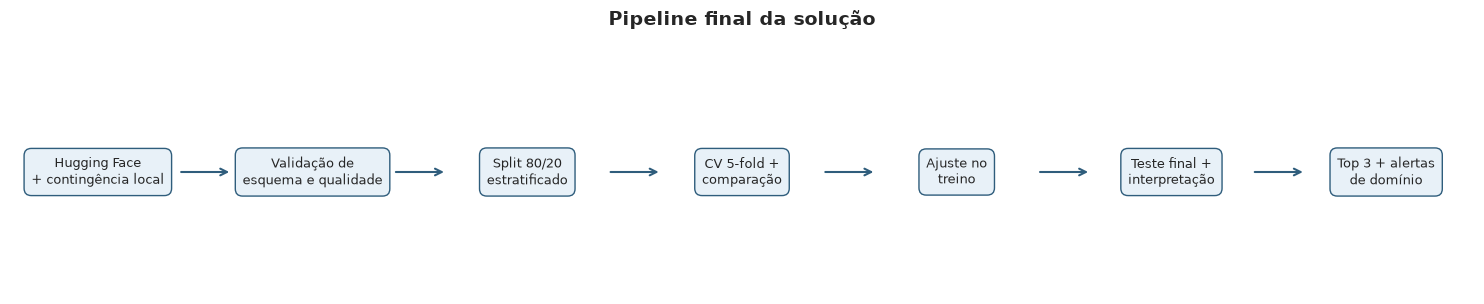

In [4]:
steps = [
    "Hugging Face\n+ contingência local",
    "Validação de\nesquema e qualidade",
    "Split 80/20\nestratificado",
    "CV 5-fold +\ncomparação",
    "Ajuste no\ntreino",
    "Teste final +\ninterpretação",
    "Top 3 + alertas\nde domínio",
]
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.axis("off")
xs = np.linspace(0.06, 0.94, len(steps))
for index, (x, label) in enumerate(zip(xs, steps)):
    ax.text(
        x,
        0.5,
        label,
        ha="center",
        va="center",
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.55", facecolor="#E8F1F8", edgecolor="#2F5D7C"),
        transform=ax.transAxes,
    )
    if index < len(steps) - 1:
        ax.annotate(
            "",
            xy=(xs[index + 1] - 0.055, 0.5),
            xytext=(x + 0.055, 0.5),
            arrowprops=dict(arrowstyle="->", color="#2F5D7C", lw=1.5),
            xycoords=ax.transAxes,
        )
ax.set_title("Pipeline final da solução", fontsize=14, fontweight="bold", pad=18)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pipeline_solucao.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Separação do teste e comparação de modelos

In [5]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = build_candidate_models(RANDOM_STATE)
comparison = compare_models(models, X_train, y_train, cv)

display(
    comparison[
        [
            "modelo",
            "f1_macro_media",
            "f1_macro_dp",
            "precision_macro_media",
            "recall_macro_media",
            "gap_f1_macro",
            "tempo_ajuste_medio_s",
        ]
    ].round(4)
)
print(f"Treino: {len(X_train)} | Teste reservado: {len(X_test)}")

/usr/local/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.12/site-packag

,modelo,f1_macro_media,f1_macro_dp,precision_macro_media,recall_macro_media,gap_f1_macro,tempo_ajuste_medio_s
0,Extra Trees,0.9662,0.0033,0.9681,0.9665,0.0338,0.7722
1,Random Forest,0.9652,0.0069,0.9673,0.9653,0.0348,1.0062
2,Regressao logistica,0.9254,0.0108,0.9294,0.9267,0.0164,0.1538
3,Arvore de decisao,0.9096,0.0067,0.9170,0.9102,0.0584,0.0093
4,Baseline,0.0040,0.0000,0.0021,0.0455,0.0000,0.0013


Treino: 1760 | Teste reservado: 440


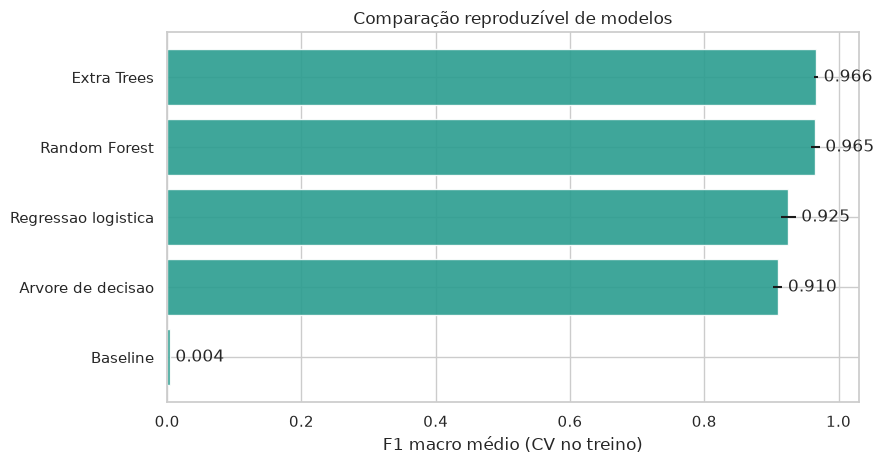

In [6]:
plot_comparison = comparison.sort_values("f1_macro_media")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(
    plot_comparison["modelo"],
    plot_comparison["f1_macro_media"],
    xerr=plot_comparison["f1_macro_dp"],
    color="#2A9D8F",
    alpha=0.9,
)
ax.set(xlabel="F1 macro médio (CV no treino)", title="Comparação reproduzível de modelos")
ax.set_xlim(0, 1.03)
for container in ax.containers:
    if hasattr(container, "datavalues"):
        ax.bar_label(container, fmt="%.3f", padding=4)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "comparacao_modelos_final.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Ajuste controlado da melhor família

A busca de hiperparâmetros é restrita ao conjunto de treino e usa as mesmas cinco partições estratificadas. O teste não participa da escolha. Entre os ensembles avaliados, a família com maior F1 macro médio é ajustada por busca aleatória com seed fixa.

In [7]:
ensemble_ranking = comparison[comparison["modelo"].isin(["Random Forest", "Extra Trees"])]
selected_family = ensemble_ranking.iloc[0]["modelo"]
search = build_tuning_search(
    family_name=selected_family,
    estimator=models[selected_family],
    cv=cv,
    seed=RANDOM_STATE,
    n_iter=18,
)
search.fit(X_train, y_train)
best_model = search.best_estimator_

tuning_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)
print(f"Família selecionada: {selected_family}")
print(f"Melhor F1 macro médio na busca: {search.best_score_:.4f}")
print("Melhores hiperparâmetros:")
display(pd.Series(search.best_params_, name="valor").to_frame())
display(
    tuning_results[
        ["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"]
    ].head(10)
)

Família selecionada: Extra Trees
Melhor F1 macro médio na busca: 0.9669
Melhores hiperparâmetros:


,valor
n_estimators,900.00
min_samples_split,8.00
min_samples_leaf,1.00
max_features,0.75
max_depth,20.00
class_weight,NaN


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.966856,0.003908,0.998011,"{'n_estimators': 700, 'min_samples_split': 8, ..."
1,1,0.966856,0.003908,0.997869,"{'n_estimators': 900, 'min_samples_split': 8, ..."
2,3,0.965196,0.002128,1.000000,"{'n_estimators': 300, 'min_samples_split': 2, ..."
3,4,0.965150,0.004928,0.993606,"{'n_estimators': 900, 'min_samples_split': 8, ..."
4,5,0.964554,0.002888,0.997301,"{'n_estimators': 700, 'min_samples_split': 4, ..."
5,6,0.964534,0.002278,0.997159,"{'n_estimators': 900, 'min_samples_split': 4, ..."
6,7,0.964517,0.005227,0.999858,"{'n_estimators': 500, 'min_samples_split': 4, ..."
7,8,0.964482,0.006702,0.994886,"{'n_estimators': 500, 'min_samples_split': 4, ..."
8,9,0.964369,0.003842,0.996165,"{'n_estimators': 700, 'min_samples_split': 8, ..."
9,10,0.963995,0.002941,0.997301,"{'n_estimators': 500, 'min_samples_split': 8, ..."


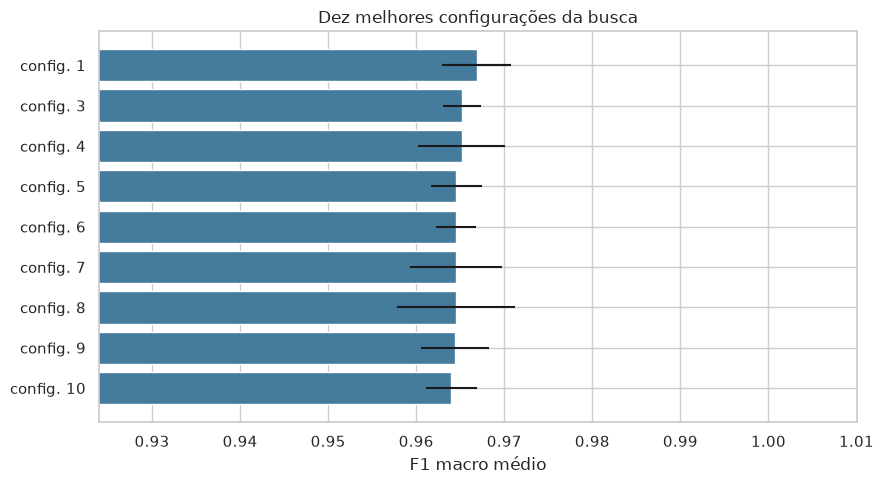

In [8]:
top_search = tuning_results.head(10).sort_values("mean_test_score")
fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"config. {int(rank)}" for rank in top_search["rank_test_score"]]
ax.barh(labels, top_search["mean_test_score"], xerr=top_search["std_test_score"], color="#457B9D")
ax.set(xlabel="F1 macro médio", title="Dez melhores configurações da busca")
ax.set_xlim(max(0, top_search["mean_test_score"].min() - 0.04), 1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "busca_hiperparametros_final.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Curva de aprendizado

,train_size,train_mean,train_std,validation_mean,validation_std
0,352,0.9968,0.0022,0.9366,0.0081
1,616,0.9975,0.0015,0.9542,0.0048
2,880,0.9976,0.0008,0.9606,0.0046
3,1144,0.9984,0.0007,0.9652,0.0034
4,1408,0.9979,0.0006,0.9669,0.0039


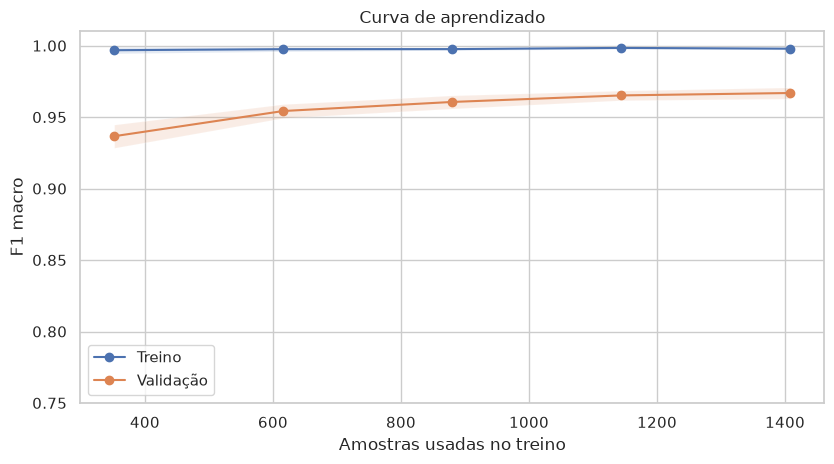

In [9]:
train_sizes, train_scores, validation_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    train_sizes=np.linspace(0.25, 1.0, 5),
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
    shuffle=True,
    random_state=RANDOM_STATE,
)
learning_data = pd.DataFrame(
    {
        "train_size": train_sizes,
        "train_mean": train_scores.mean(axis=1),
        "train_std": train_scores.std(axis=1),
        "validation_mean": validation_scores.mean(axis=1),
        "validation_std": validation_scores.std(axis=1),
    }
)
display(learning_data.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(train_sizes, learning_data["train_mean"], marker="o", label="Treino")
ax.plot(train_sizes, learning_data["validation_mean"], marker="o", label="Validação")
ax.fill_between(
    train_sizes,
    learning_data["train_mean"] - learning_data["train_std"],
    learning_data["train_mean"] + learning_data["train_std"],
    alpha=0.15,
)
ax.fill_between(
    train_sizes,
    learning_data["validation_mean"] - learning_data["validation_std"],
    learning_data["validation_mean"] + learning_data["validation_std"],
    alpha=0.15,
)
ax.set(xlabel="Amostras usadas no treino", ylabel="F1 macro", title="Curva de aprendizado")
ax.legend()
ax.set_ylim(0.75, 1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "curva_aprendizado.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Avaliação final no teste reservado

O conjunto de teste é usado somente agora. Além de precision, recall e F1 macro/weighted, são calculados top-3 accuracy e log loss. A primeira mede se a cultura real aparece entre as três alternativas mais prováveis; a segunda penaliza previsões probabilísticas excessivamente confiantes e erradas.

In [10]:
test_metrics, predictions, probabilities = evaluate_classifier(best_model, X_test, y_test)
metrics_table = pd.Series(test_metrics, name="resultado").to_frame()
display(metrics_table.round(4))

report = pd.DataFrame(
    classification_report(y_test, predictions, output_dict=True, zero_division=0)
).T
class_report = report.loc[sorted(y.unique()), ["precision", "recall", "f1-score", "support"]]
display(class_report.sort_values("f1-score").round(4))

,resultado
accuracy,0.9750
balanced_accuracy,0.9750
precision_macro,0.9761
recall_macro,0.9750
f1_macro,0.9750
f1_weighted,0.9750
top3_accuracy,1.0000
log_loss,0.1797
errors,11.0000
test_observations,440.0000


,precision,recall,f1-score,support
kidneybeans,0.9444,0.85,0.8947,20.0
chickpea,0.8636,0.95,0.9048,20.0
jute,0.9474,0.90,0.9231,20.0
rice,0.9048,0.95,0.9268,20.0
pomegranate,1.0000,0.90,0.9474,20.0
coconut,0.9091,1.00,0.9524,20.0
cotton,1.0000,0.95,0.9744,20.0
pigeonpeas,1.0000,0.95,0.9744,20.0
watermelon,0.9524,1.00,0.9756,20.0
blackgram,0.9524,1.00,0.9756,20.0


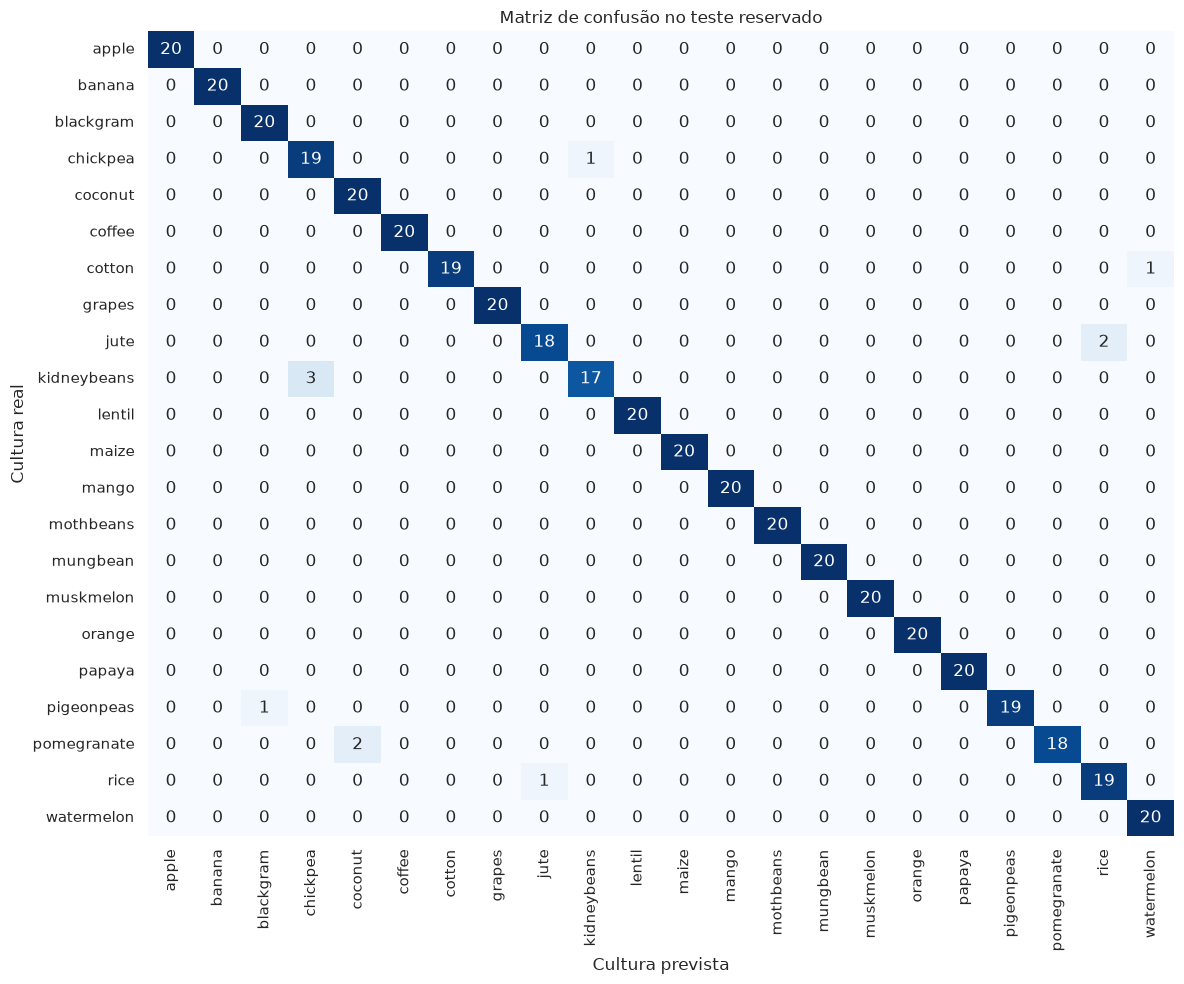

,real,predicted,quantity
0,kidneybeans,chickpea,3
1,pomegranate,coconut,2
2,jute,rice,2
3,chickpea,kidneybeans,1
4,rice,jute,1
5,cotton,watermelon,1
6,pigeonpeas,blackgram,1


In [11]:
labels = sorted(y.unique())
matrix = confusion_matrix(y_test, predictions, labels=labels)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(matrix, cmap="Blues", annot=True, fmt="d", cbar=False, ax=ax)
ax.set(
    title="Matriz de confusão no teste reservado",
    xlabel="Cultura prevista",
    ylabel="Cultura real",
)
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels, rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "matriz_confusao_final.png", dpi=180, bbox_inches="tight")
plt.show()

errors = pd.DataFrame({"real": y_test.to_numpy(), "predicted": predictions})
errors = errors.query("real != predicted")
error_pairs = (
    errors.value_counts(["real", "predicted"])
    .rename("quantity")
    .reset_index()
)
display(error_pairs.head(12))

## 8. Interpretação: importância por permutação

,feature,importance_mean,importance_std
4,humidity,0.4264,0.0259
0,N,0.3919,0.0164
6,rainfall,0.2881,0.0178
1,P,0.2118,0.0148
2,K,0.1473,0.0091
5,ph,0.0588,0.0078
3,temperature,0.0523,0.0096


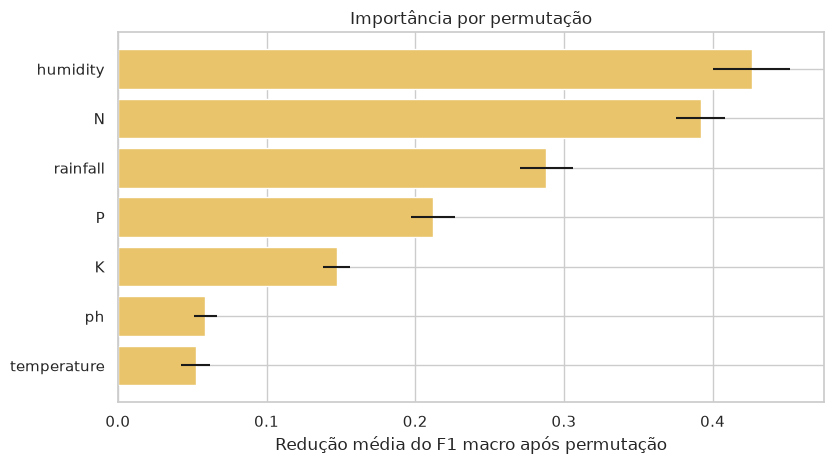

In [12]:
permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame(
    {
        "feature": FEATURES,
        "importance_mean": permutation.importances_mean,
        "importance_std": permutation.importances_std,
    }
).sort_values("importance_mean", ascending=False)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
plot_importance = importance.sort_values("importance_mean")
ax.barh(
    plot_importance["feature"],
    plot_importance["importance_mean"],
    xerr=plot_importance["importance_std"],
    color="#E9C46A",
)
ax.set(xlabel="Redução média do F1 macro após permutação", title="Importância por permutação")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "importancia_permutacao.png", dpi=180, bbox_inches="tight")
plt.show()

A importância por permutação mede quanto o desempenho diminui ao embaralhar cada atributo. Ela é mais comparável entre variáveis do que a importância interna baseada em impureza, mas ainda descreve associação preditiva no dataset, não causalidade agronômica.

## 9. Confiança, top-3 e análise dos erros

,confidence_band,observations,accuracy,mean_confidence
0,"(-0.001, 0.6]",37,0.7838,0.5077
1,"(0.6, 0.7]",36,0.9444,0.6503
2,"(0.7, 0.8]",37,1.0000,0.7565
3,"(0.8, 0.9]",97,0.9897,0.8568
4,"(0.9, 0.95]",60,1.0000,0.9242
5,"(0.95, 1.0]",173,1.0000,0.9804


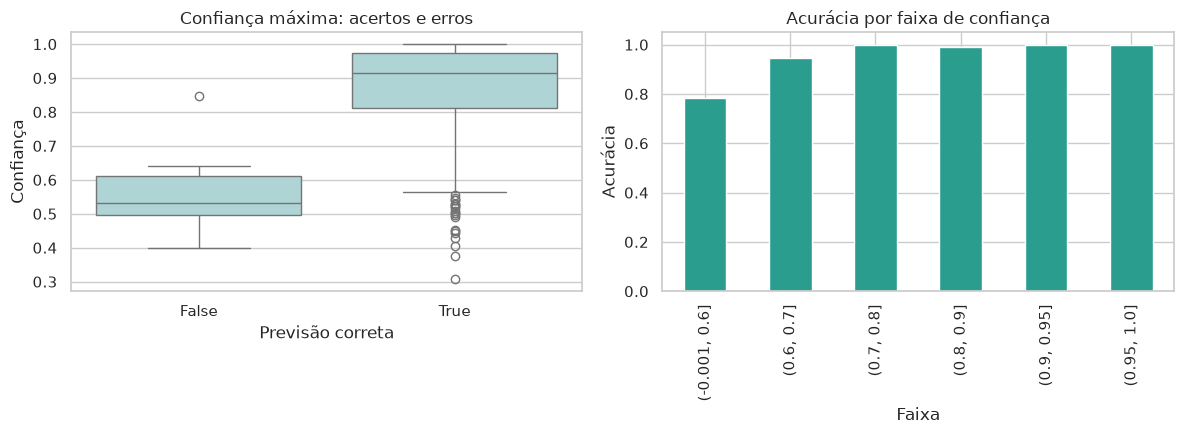

In [13]:
confidence_detail, confidence_summary = confidence_diagnostics(
    y_test, predictions, probabilities
)
display(confidence_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=confidence_detail, x="correct", y="confidence", ax=axes[0], color="#A8DADC")
axes[0].set(title="Confiança máxima: acertos e erros", xlabel="Previsão correta", ylabel="Confiança")
confidence_summary.plot(
    x="confidence_band", y="accuracy", kind="bar", ax=axes[1], color="#2A9D8F", legend=False
)
axes[1].set(title="Acurácia por faixa de confiança", xlabel="Faixa", ylabel="Acurácia", ylim=(0, 1.05))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confianca_modelo.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Robustez aos registros de umidade acima de 100

In [14]:
filtered = df.loc[df["humidity"] <= 100].copy()
full_scores = cross_val_score(
    best_model, df[FEATURES], df[TARGET], cv=cv, scoring="f1_macro", n_jobs=1
)
filtered_scores = cross_val_score(
    best_model,
    filtered[FEATURES],
    filtered[TARGET],
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
)
sensitivity = pd.DataFrame(
    {
        "scenario": ["Base completa", "Sem umidade acima de 100"],
        "records": [len(df), len(filtered)],
        "f1_macro_mean": [full_scores.mean(), filtered_scores.mean()],
        "f1_macro_std": [full_scores.std(), filtered_scores.std()],
    }
)
display(sensitivity.round(4))

,scenario,records,f1_macro_mean,f1_macro_std
0,Base completa,2200,0.9753,0.0064
1,Sem umidade acima de 100,2181,0.9753,0.0108


## 11. Protótipo operacional com salvaguardas

O protótipo retorna as três culturas mais compatíveis e sinaliza entradas fora das faixas observadas no treino. Isso não resolve a ausência de validação regional, mas evita que uma extrapolação seja apresentada silenciosamente como recomendação confiável.

In [15]:
ranges = feature_ranges(X_train)
example = X_test.iloc[[0]]
recommendations, domain_warnings = recommend_top_k(best_model, example, ranges, top_k=3)

display(example)
display(recommendations.assign(compatibility=lambda data: data["compatibility"].round(4)))
print(f"Cultura real deste exemplo: {y_test.loc[example.index[0]]}")
print("Alertas de domínio:", domain_warnings or "nenhum")

,N,P,K,temperature,humidity,ph,rainfall
288,22.064293,5.169319,19.073217,26.462232,92.443487,7.480682,127.985583


,rank,crop,compatibility
0,1,orange,0.7860
1,2,coconut,0.1805
2,3,pomegranate,0.0239


Cultura real deste exemplo: orange
Alertas de domínio: nenhum


## 12. Exportação reproduzível dos artefatos

Os arquivos exportados permitem auditar a execução, reproduzir o relatório e reutilizar o estimador.

In [16]:
comparison.to_csv(RESULTS_DIR / "comparacao_modelos_final.csv", index=False)
tuning_results.to_csv(RESULTS_DIR / "busca_hiperparametros_final.csv", index=False)
learning_data.to_csv(RESULTS_DIR / "curva_aprendizado.csv", index=False)
metrics_table.to_csv(RESULTS_DIR / "metricas_teste_final.csv")
class_report.to_csv(RESULTS_DIR / "relatorio_classificacao_final.csv")
error_pairs.to_csv(RESULTS_DIR / "erros_teste_final.csv", index=False)
importance.to_csv(RESULTS_DIR / "importancia_permutacao.csv", index=False)
confidence_detail.to_csv(RESULTS_DIR / "confianca_detalhe.csv", index=False)
confidence_summary.to_csv(RESULTS_DIR / "confianca_resumo.csv", index=False)
sensitivity.to_csv(RESULTS_DIR / "sensibilidade_umidade_final.csv", index=False)
ranges.to_csv(RESULTS_DIR / "faixas_treino.csv")
recommendations.to_csv(RESULTS_DIR / "recomendacao_exemplo.csv", index=False)

model_path = MODELS_DIR / "modelo_cultivo_final.joblib"
joblib.dump(best_model, model_path)

metadata = {
    "dataset": DATASET_ID,
    "source": provenance,
    "features": FEATURES,
    "target": TARGET,
    "seed": RANDOM_STATE,
    "split": {"train": len(X_train), "test": len(X_test), "test_size": 0.20},
    "validation": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
    "selected_family": selected_family,
    "best_parameters": search.best_params_,
    "best_cv_f1_macro": search.best_score_,
    "test_metrics": test_metrics,
    "software": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
    },
}
with open(RESULTS_DIR / "metadados_modelo_final.json", "w", encoding="utf-8") as stream:
    json.dump(metadata, stream, ensure_ascii=False, indent=2)

print(f"Modelo salvo em: {model_path}")
print("Tabelas e metadados salvos em results/; figuras salvas em figures/.")

Modelo salvo em: /workspace/models/modelo_cultivo_final.joblib
Tabelas e metadados salvos em results/; figuras salvas em figures/.


## 13. Conclusões, viabilidade e impacto

- O pipeline compara alternativas sob as mesmas partições, ajusta hiperparâmetros somente no treino e mantém um teste reservado.
- O F1 macro é a métrica principal porque representa igualmente as 22 culturas; top-3 accuracy complementa a leitura operacional.
- As importâncias e os erros devem ser interpretados como comportamento do modelo dentro da base, sem inferência causal.
- A análise de sensibilidade verifica se os 19 registros de umidade acima de 100 alteram substancialmente o desempenho, mas não determina sua validade física.
- O protótipo é tecnicamente viável como apoio experimental à decisão, com retorno de três alternativas e alerta de extrapolação.